<a href="https://colab.research.google.com/github/AyatMaged/AI-Alert-Triage/blob/main/notebooks/01_data_analysis_and_cleaning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Part 1: Data Analysis, Feature Engineering and Cleaning
**AI-Powered Cybersecurity Alert Triage System** | Team TriageAI | DEPI Graduation Project

**Goal:** understand the opensec-triage dataset, select the features that really matter, and prepare clean data for model training.

**Dataset:** tegridydev/opensec-triage (Hugging Face, CC BY 4.0) | **Role:** Data Analysis & Dataset Quality: Ayat Maged Fathy Abdelazeem

## Key terms
- **TF-IDF:** turns text into numbers; a word gets a higher weight when it is frequent in one alert but rare across all alerts.
- **Chi-square test:** a statistical test that measures how strongly a word is related to a class.
- **Data leakage:** a feature that reveals the answer directly, so a model looks accurate without really learning.
- **Z-score and IQR:** two ways to detect values far from the normal range. Z-score fits bell-shaped data; IQR fits skewed data.
- **Clipping:** replacing an extreme value with the nearest allowed limit instead of deleting the alert.
- **Median imputation:** filling a missing number with the middle value of the column.
- **TruncatedSVD:** shrinks hundreds of features into 2 so they can be drawn on a plot.

In [10]:
# 1. Libraries
!pip install -q datasets

import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from datasets import load_dataset
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import VarianceThreshold, SelectKBest, chi2
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

## 1. Setup
- Installed the Hugging Face `datasets` library to download the data.
- Imported the tools we use: pandas and numpy (data), matplotlib and seaborn (plots), scipy (statistics), scikit-learn (feature extraction and selection).

Shape: (50000, 3)
Split sizes: {'train': 40000, 'validation': 5000, 'test': 5000}


,text,target,split
0,Dns control audit on LEGAL-ASSET-f795ba9c6d1dd07e recorded that an authoritative DNS record was updated. The event r...,suspicious,train
1,Kubernetes audit on COMMUNICATIONS-ASSET-a673821b24e13ca1 recorded that a principal opened a pod exec session and re...,suspicious,train
2,Oauth audit on RESEARCH-ASSET-8e0914b2a25c8284 recorded that an application received consent for additional account ...,misconfiguration,train
3,Egress flow logs on COMMUNICATIONS-ASSET-4ab4de57f4047912 recorded that a workload opened an encrypted connection to...,misconfiguration,train
4,Device and file audit on PEOPLE-ASSET-77633f2e82ac55d6 recorded that files were copied to a removable storage device...,suspicious,train


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    50000 non-null  object
 1   target  50000 non-null  object
 2   split   50000 non-null  object
dtypes: object(3)
memory usage: 1.1+ MB


,count,unique,top,freq
text,50000,50000,Dns control audit on LEGAL-ASSET-f795ba9c6d1dd07e recorded that an authoritative DNS record was updated. The event r...,1
target,50000,7,suspicious,7143
split,50000,3,train,40000



Missing values:
 text      0
target    0
split     0
dtype: int64

Duplicated texts: 0


,count
target,
suspicious,7143
misconfiguration,7143
expected_admin,7143
malicious,7143
authorised_testing,7143
benign,7143
unknown,7142


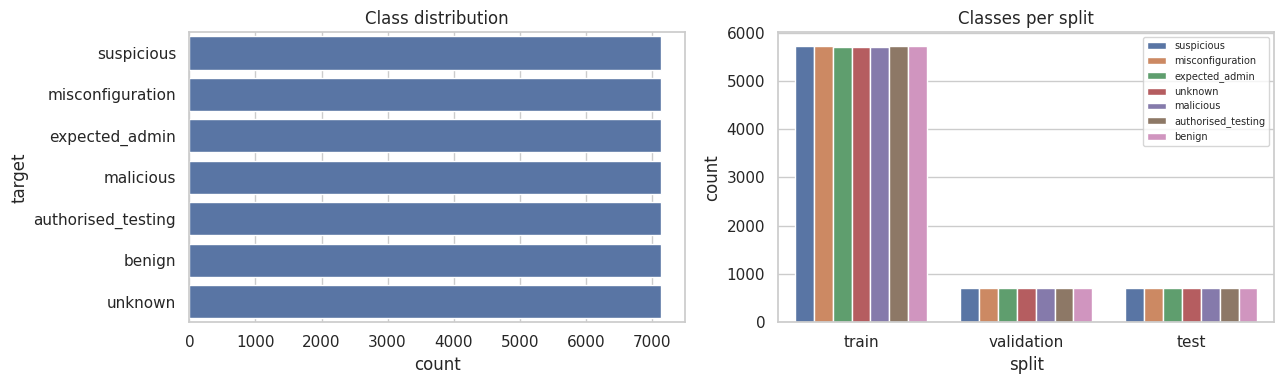

In [11]:
# 2. Load dataset and EDA
ds = load_dataset("tegridydev/opensec-triage")
train = ds["train"].to_pandas()
val = ds["validation"].to_pandas()
test = ds["test"].to_pandas()

df = pd.concat(
    [train.assign(split="train"), val.assign(split="validation"), test.assign(split="test")],
    ignore_index=True,
)

print("Shape:", df.shape)
print("Split sizes:", df.split.value_counts().to_dict())
display(df.head())

df.info()
display(df.describe(include="all").T)

print("\nMissing values:\n", df.isna().sum())
print("\nDuplicated texts:", df.text.duplicated().sum())

class_counts = df.target.value_counts()
display(class_counts.to_frame("count"))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(data=df, y="target", order=class_counts.index, ax=ax[0])
ax[0].set_title("Class distribution")
sns.countplot(data=df, x="split", hue="target", ax=ax[1])
ax[1].set_title("Classes per split")
ax[1].legend(fontsize=7, loc="upper right")
plt.tight_layout()
plt.show()

## 2. Loading the data and EDA
- Dataset: opensec-triage, 50,000 synthetic security alerts (40,000 train, 5,000 validation, 5,000 test).
- Each alert has two columns: `text` (event description plus evidence) and `target` (the class).
- 7 balanced classes: malicious, suspicious, benign, expected_admin, authorised_testing, misconfiguration, unknown.
- Checks: no missing values and no duplicated texts.
- Plots: bar charts of the class distribution overall and per split.

Dropped constant features: ['n_digits', 'n_sentences']
Dropped correlated features (|r| > 0.9): []


,F,p_value,mutual_info
n_ids,inf,0.0,0.598706
n_semicolons,1.359215e+04,0.0,0.474804
n_commas,3.720632e+03,0.0,0.313801
avg_word_len,1.686087e+03,0.0,0.295885
n_chars,2.119788e+03,0.0,0.163965
n_words,1.377316e+03,0.0,0.148271


Dropped leaky features (constant within every class): ['n_ids']
Kept numeric features: ['n_chars', 'n_words', 'avg_word_len', 'n_commas', 'n_semicolons']


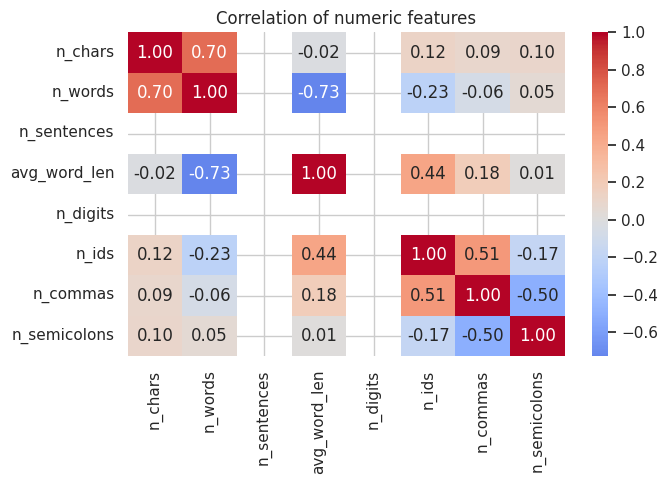

TF-IDF features before selection: 1856
Terms kept (p < 0.01): 782 | dropped: 1074
TF-IDF features after selection: 300


,mean_chi2
event,0.014424
context,0.000000
evidence,2287.994535


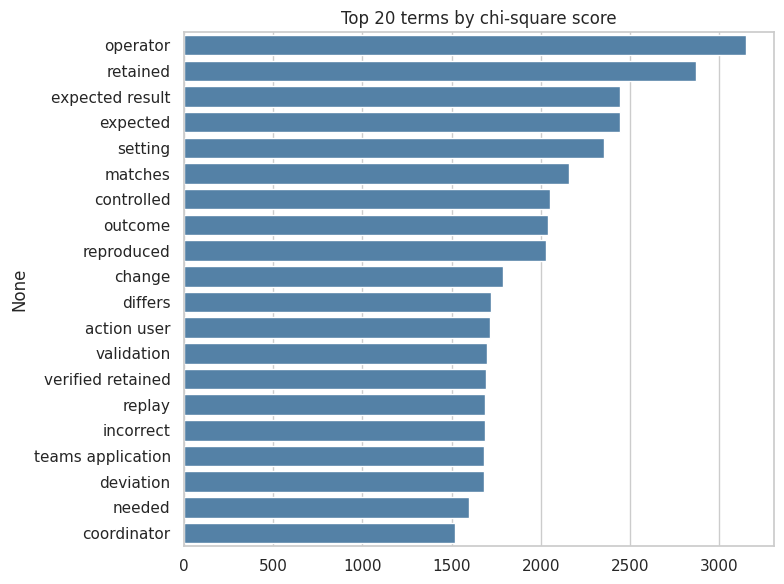

Low-signal text blocks (excluded from model input): ['event', 'context']
Model input example:
 the resource scope differs from the actor’s baseline and the owner cannot identify a matching work request. no independent source confirms compromise, and no verified change or assessment explains the deviation.


In [12]:
# 3. Feature engineering and selection
from sklearn.feature_selection import f_classif, mutual_info_classif

ID_PATTERNS = [r"\b[A-Z]+-ASSET-[0-9a-f]+\b", r"principal-[0-9a-f]+", r"\b[A-Z]{2,}-[0-9a-f]{6,}\b"]

def strip_ids(text):
    for p in ID_PATTERNS:
        text = re.sub(p, " ", text)
    return re.sub(r"\s+", " ", text).strip()

SENT_SPLIT = re.compile(r"(?<=\.)\s+")
parts = df.text.apply(lambda t: SENT_SPLIT.split(t.strip()))

# structural features
df["n_chars"] = df.text.str.len()
df["n_words"] = df.text.str.split().str.len()
df["n_sentences"] = parts.str.len()
df["avg_word_len"] = df.n_chars / df.n_words
df["n_ids"] = sum(df.text.str.count(p) for p in ID_PATTERNS)
df["n_commas"] = df.text.str.count(",")
df["n_semicolons"] = df.text.str.count(";")

# text blocks: event, context (sentences 2-5), evidence (sentences 6+)
df["event"] = parts.str[0].apply(strip_ids)
df["context"] = parts.str[1:5].str.join(" ").apply(strip_ids)
df["evidence"] = parts.str[5:].str.join(" ").apply(strip_ids)
df["text_clean"] = df.text.apply(strip_ids).str.lower()
df["n_digits"] = df.text_clean.str.count(r"\d")

num_cols = ["n_chars", "n_words", "n_sentences", "avg_word_len", "n_digits", "n_ids", "n_commas", "n_semicolons"]

# split first, so selection is fitted on train only
train_df = df[df.split == "train"]
val_df = df[df.split == "validation"]
test_df = df[df.split == "test"]

le = LabelEncoder().fit(train_df.target)
y_train, y_val, y_test = (le.transform(d.target) for d in (train_df, val_df, test_df))

# numeric features: drop constants, then highly correlated ones
vt = VarianceThreshold(threshold=1e-8).fit(train_df[num_cols])
kept_num = [c for c, keep in zip(num_cols, vt.get_support()) if keep]
print("Dropped constant features:", sorted(set(num_cols) - set(kept_num)))

corr = train_df[kept_num].corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
drop_corr = [c for c in upper.columns if (upper[c] > 0.9).any()]
kept_num = [c for c in kept_num if c not in drop_corr]
print("Dropped correlated features (|r| > 0.9):", drop_corr)

# relevance to the class (ANOVA F-test and mutual information)
F, p = f_classif(train_df[kept_num], y_train)
mi = mutual_info_classif(train_df[kept_num], y_train, random_state=42)
relevance = pd.DataFrame({"F": F, "p_value": p, "mutual_info": mi}, index=kept_num).sort_values("mutual_info", ascending=False)
display(relevance)

# leakage check: a feature that is constant inside every class is a direct proxy for the label
leaky = [c for c in kept_num if (train_df.groupby("target")[c].std().fillna(0) == 0).all()]
print("Dropped leaky features (constant within every class):", leaky)
kept_num = [c for c in kept_num if c not in leaky]
print("Kept numeric features:", kept_num)

plt.figure(figsize=(7, 5))
sns.heatmap(train_df[[c for c in num_cols if c in train_df]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation of numeric features")
plt.tight_layout()
plt.show()

# text features: TF-IDF with stop words removed and rare terms ignored
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=5, max_df=0.95, sublinear_tf=True, stop_words="english")
X_train_all = tfidf.fit_transform(train_df.text_clean)
terms = np.array(tfidf.get_feature_names_out())
print("TF-IDF features before selection:", X_train_all.shape[1])

# chi-square selection: keep only terms statistically related to the class
chi_scores, p_values = chi2(X_train_all, y_train)
useful = p_values < 0.01
print("Terms kept (p < 0.01):", int(useful.sum()), "| dropped:", int((~useful).sum()))

selector = SelectKBest(chi2, k=min(300, int(useful.sum()))).fit(X_train_all, y_train)
selected_terms = terms[selector.get_support()]
X_train = selector.transform(X_train_all)
X_val = selector.transform(tfidf.transform(val_df.text_clean))
X_test = selector.transform(tfidf.transform(test_df.text_clean))
print("TF-IDF features after selection:", X_train.shape[1])

# which text block carries the signal: mean chi2 of selected terms found in each block
def block_signal(col):
    v = TfidfVectorizer(vocabulary=selected_terms, ngram_range=(1, 2), stop_words=None)
    m = v.fit_transform(train_df[col].str.lower())
    s, _ = chi2(m, y_train)
    return np.nan_to_num(s).mean()

signal = pd.Series({c: block_signal(c) for c in ["event", "context", "evidence"]}, name="mean_chi2")
display(signal.to_frame())

top = pd.Series(chi_scores, index=terms).sort_values(ascending=False).head(20)
plt.figure(figsize=(8, 6))
sns.barplot(x=top.values, y=top.index, color="steelblue")
plt.title("Top 20 terms by chi-square score")
plt.tight_layout()
plt.show()

# down-weight uninformative blocks: keep only the informative text blocks as model input
weak_blocks = signal[signal < signal.max() * 0.1].index.tolist()
print("Low-signal text blocks (excluded from model input):", weak_blocks)
df["model_text"] = df[[c for c in ["event", "context", "evidence"] if c not in weak_blocks]].agg(" ".join, axis=1).str.lower()
print("Model input example:\n", df.model_text.iloc[0])

## 3. Feature engineering and selection
**Features we built**
- Numeric: number of characters, words, sentences, average word length, commas, semicolons.
- Text blocks: each alert has 7 sentences, which we split into event, context and evidence.
- Random IDs (asset, principal, ticket) were removed from the text because they carry no meaning.

**Numeric feature selection**
- Dropped constant features (`n_sentences` is always 7).
- Dropped highly correlated features (|r| > 0.9). None found.
- Ran an F-test and mutual information against the class.
- Leakage check: `n_ids` is constant inside each class, so it reveals the label without understanding the text. It was removed.

**Text feature selection (TF-IDF + chi-square)**
- TF-IDF created 1,856 word and phrase features.
- 782 were statistically related to the class (p < 0.01); 1,074 were useless and dropped.
- We kept the 300 best features.

**Which part of the alert matters?**
- Mean chi-square score: evidence = 2,288, event = 0.014, context = 0.
- Only the evidence sentences identify the class, so event and context were excluded from the model input.

Missing values per column:
 text            0
target          0
n_chars         0
n_words         0
n_sentences     0
avg_word_len    0
n_digits        0
n_ids           0
n_commas        0
n_semicolons    0
dtype: int64
Rows: 50000 -> 50000 (removed 0)


,feature,skew,kurtosis,method,lower,upper,outliers,pct
0,n_chars,-0.06,-0.08,z-score,510.76,620.24,122,0.24
1,n_words,-0.09,-0.08,z-score,60.89,80.91,68,0.14
2,avg_word_len,0.34,0.02,z-score,7.18,8.79,166,0.33


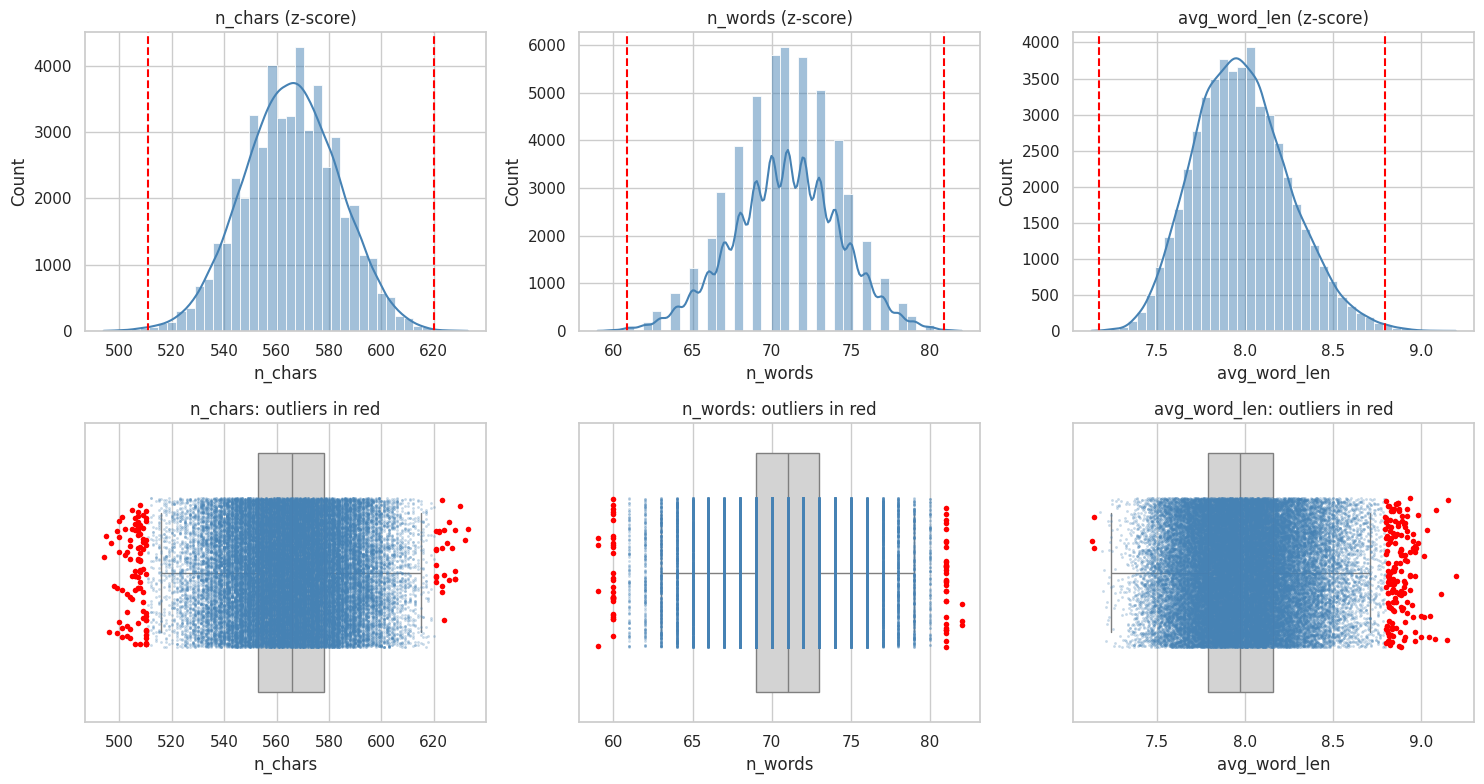

Clean dataset shape: (50000, 16)


,count,mean,std,min,25%,50%,75%,max
n_chars,50000.0,565.508801,18.208178,510.764151,553.000000,566.000000,578.00000,620.239569
n_words,50000.0,70.897340,3.333854,60.887741,69.000000,71.000000,73.00000,80.905859
avg_word_len,50000.0,7.985387,0.268854,7.176362,7.791667,7.971429,8.15942,8.794959


In [13]:
# 4. Data cleaning: missing values and outliers
before = len(df)
print("Missing values per column:\n", df[["text", "target"] + num_cols].isna().sum())

# text: empty strings are missing; target cannot be imputed, so such rows are dropped
df["text"] = df.text.replace(r"^\s*$", np.nan, regex=True)
df = df.dropna(subset=["text", "target"])

# numeric features: median imputation (robust to skew)
for c in num_cols:
    if df[c].isna().any():
        df[c] = df[c].fillna(df[c].median())

df = df.drop_duplicates(subset="text").reset_index(drop=True)
print(f"Rows: {before} -> {len(df)} (removed {before - len(df)})")

# choose the outlier method per feature: z-score if roughly normal, IQR if skewed
check_cols = [c for c in kept_num if df[c].nunique() > 10]
rows, bounds = [], {}
for c in check_cols:
    skew = stats.skew(df[c])
    kurt = stats.kurtosis(df[c])
    if abs(skew) <= 0.5 and abs(kurt) <= 1:
        method = "z-score"
        mu, sd = df[c].mean(), df[c].std()
        lo, hi = mu - 3 * sd, mu + 3 * sd
    else:
        method = "IQR"
        q1, q3 = df[c].quantile([0.25, 0.75])
        lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    bounds[c] = (lo, hi)
    n_out = int(((df[c] < lo) | (df[c] > hi)).sum())
    rows.append({"feature": c, "skew": round(skew, 2), "kurtosis": round(kurt, 2),
                 "method": method, "lower": round(lo, 2), "upper": round(hi, 2),
                 "outliers": n_out, "pct": round(100 * n_out / len(df), 2)})
outlier_report = pd.DataFrame(rows)
display(outlier_report)

fig, axes = plt.subplots(2, len(check_cols), figsize=(5 * len(check_cols), 8), squeeze=False)
for i, c in enumerate(check_cols):
    lo, hi = bounds[c]
    is_out = (df[c] < lo) | (df[c] > hi)
    sns.histplot(df[c], bins=40, kde=True, ax=axes[0, i], color="steelblue")
    axes[0, i].axvline(lo, color="red", ls="--")
    axes[0, i].axvline(hi, color="red", ls="--")
    axes[0, i].set_title(f"{c} ({outlier_report.loc[i, 'method']})")
    sns.boxplot(x=df[c], ax=axes[1, i], color="lightgray", showfliers=False)
    sns.stripplot(x=df.loc[~is_out, c], ax=axes[1, i], color="steelblue", size=2, alpha=0.3, jitter=0.25)
    sns.stripplot(x=df.loc[is_out, c], ax=axes[1, i], color="red", size=4, jitter=0.25)
    axes[1, i].set_title(f"{c}: outliers in red")
plt.tight_layout()
plt.show()

# treatment: clip values to the bounds (keeps every alert, limits extreme influence)
df_clean = df.copy()
for c, (lo, hi) in bounds.items():
    df_clean[c] = df_clean[c].clip(lo, hi)

print("Clean dataset shape:", df_clean.shape)
display(df_clean[check_cols].describe().T)
df_clean.to_csv("opensec_clean.csv", index=False)

## 4. Data cleaning
**Missing values**
- No missing values in any column, and no duplicates (50,000 rows before and after).
- The code still handles them: rows with empty text or label are dropped (a label cannot be guessed), and missing numeric values are filled with the median, which is robust to skew.

**Outliers**
- The method is chosen automatically for each feature: z-score if the distribution is close to normal, IQR if it is skewed.
- Outliers found: n_chars 122 (0.24%), n_words 68 (0.14%), avg_word_len 166 (0.33%).
- All are below 0.4%, so they are normal tails of the distribution and not errors.
- Treatment: values were clipped to the bounds, so no alert is removed.
- Plots: a histogram with the cut-off lines and a box plot with outliers in red.

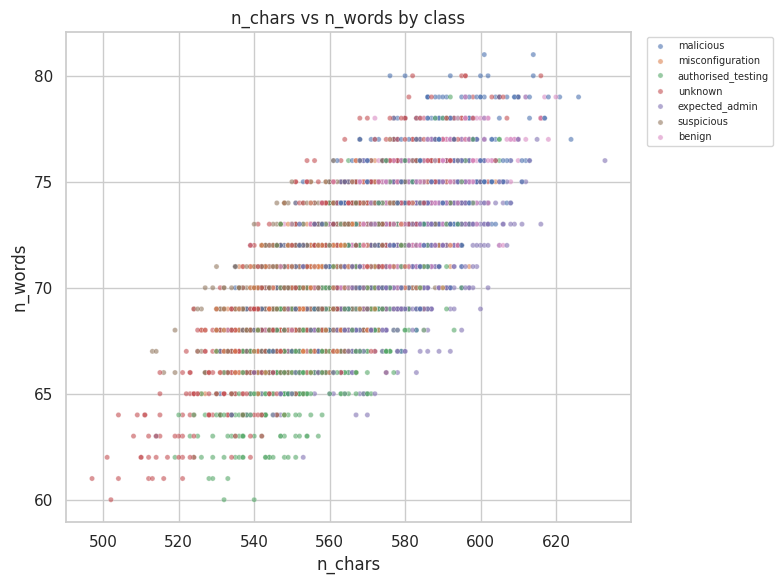

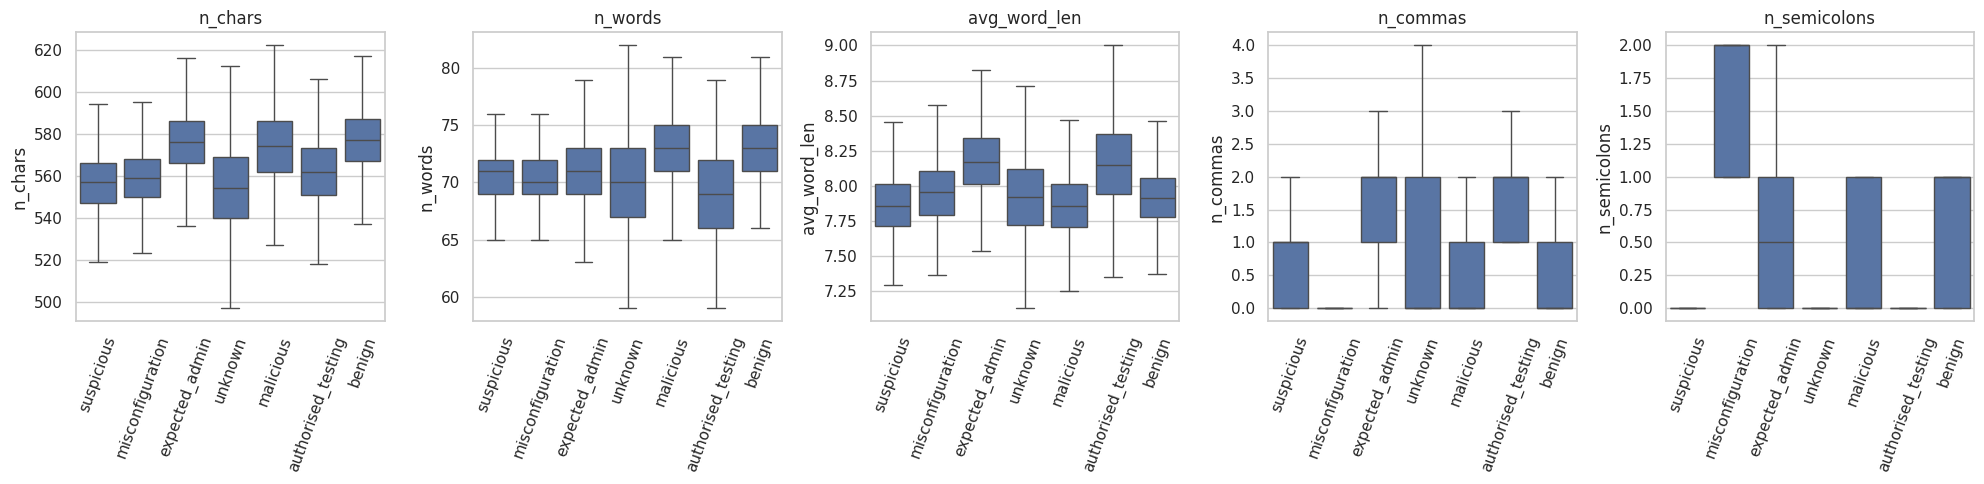

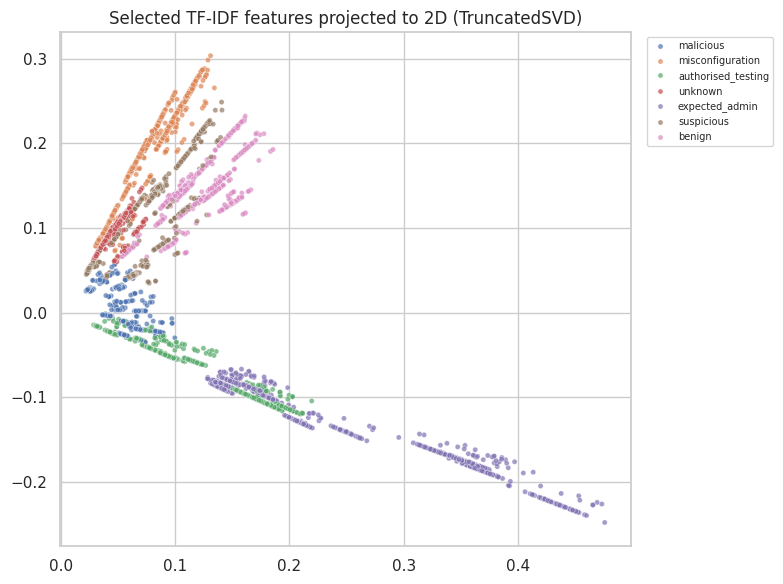

In [14]:
# 5. Scatter plots and class-wise box plots
from sklearn.decomposition import TruncatedSVD

sample = train_df.sample(min(5000, len(train_df)), random_state=42)

plt.figure(figsize=(8, 6))
sns.scatterplot(data=sample, x="n_chars", y="n_words", hue="target", s=14, alpha=0.6)
plt.title("n_chars vs n_words by class")
plt.legend(fontsize=7, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, len(kept_num), figsize=(4 * len(kept_num), 5))
for ax, c in zip(np.atleast_1d(axes), kept_num):
    sns.boxplot(data=train_df, x="target", y=c, ax=ax, showfliers=False)
    ax.set_title(c)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=70)
plt.tight_layout()
plt.show()

idx = np.random.RandomState(42).choice(X_train.shape[0], min(5000, X_train.shape[0]), replace=False)
coords = TruncatedSVD(n_components=2, random_state=42).fit_transform(X_train[idx])
plt.figure(figsize=(8, 6))
sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=le.inverse_transform(y_train[idx]), s=14, alpha=0.7)
plt.title("Selected TF-IDF features projected to 2D (TruncatedSVD)")
plt.legend(fontsize=7, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 5. Visual analysis by class
- Scatter plot of n_chars vs n_words, colored by class: shows whether length separates the classes.
- Box plots of each numeric feature per class: compares the distributions between classes.
- 2D projection (TruncatedSVD) of the 300 selected TF-IDF features: if the classes form separate groups, the evidence text alone is enough to tell them apart.